In [1]:
import pandas as pd 

df = pd.read_csv("../data/raw/credit_risk_dataset.csv")
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [2]:
print(df.shape, df.dtypes, sep="/")

(32581, 12)/person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object


In [3]:
info = pd.DataFrame({
    'dtype' : df.dtypes,
    'missing': df.isnull().sum(),
    'missing_%': (df.isnull().sum() / len(df) * 100).round(2)
})
print(info.to_string())

                              dtype  missing  missing_%
person_age                    int64        0       0.00
person_income                 int64        0       0.00
person_home_ownership           str        0       0.00
person_emp_length           float64      895       2.75
loan_intent                     str        0       0.00
loan_grade                      str        0       0.00
loan_amnt                     int64        0       0.00
loan_int_rate               float64     3116       9.56
loan_status                   int64        0       0.00
loan_percent_income         float64        0       0.00
cb_person_default_on_file       str        0       0.00
cb_person_cred_hist_length    int64        0       0.00


In [4]:
print("duplikat :", df.duplicated().sum())

duplikat : 165


In [5]:
loan_intent_count = df["loan_intent"].value_counts()
loan_intent_pct = (df["loan_intent"].value_counts(normalize=True) * 100).map(lambda x: f"{x:.2f}%")

pd.DataFrame({
    "Count": loan_intent_count,
    "Proportion": loan_intent_pct
})

,Count,Proportion
loan_intent,,
EDUCATION,6453,19.81%
MEDICAL,6071,18.63%
VENTURE,5719,17.55%
PERSONAL,5521,16.95%
DEBTCONSOLIDATION,5212,16.00%
HOMEIMPROVEMENT,3605,11.06%


In [7]:
import matplotlib.pyplot as plt

C:\Users\APTIKA\AppData\Local\Temp\ipykernel_22940\1980735062.py:21: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\APTIKA 2025\RIMA\credit-risk-predicition\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


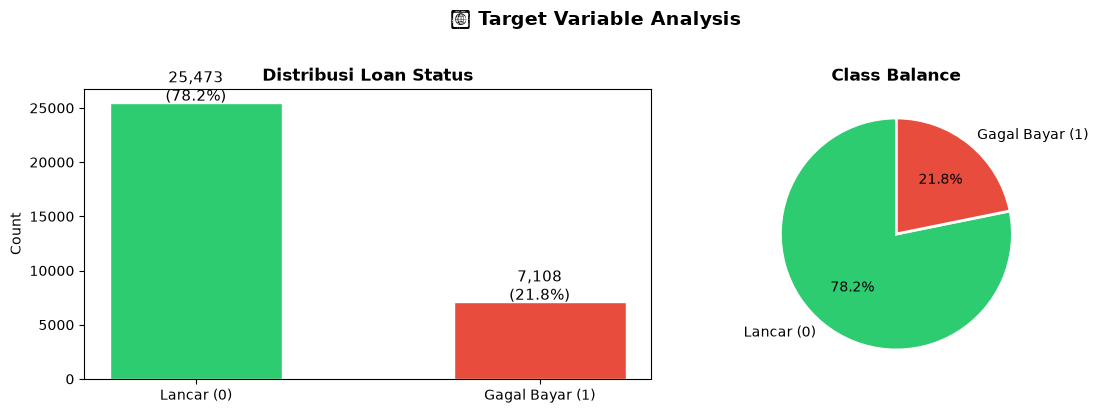


💡 Insight: Dataset is imbalanced — 21.8% defaults.
This means a naive model predicting 'Lancar' would get ~78% accuracy
We must optimize for BUSINESS COST, not just accuracy


In [9]:
# Target variable distribution
counts = df["loan_status"].value_counts()
labels = ["Lancar (0)", "Gagal Bayar (1)"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar Chart
axes[0].bar(labels, counts.values, color=['#2ecc71', '#e74c3c'], edgecolor='white', width=0.5)
axes[0].set_title('Distribusi Loan Status', fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 200, f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center', fontsize=11)
    
# Pie chart
axes[1].pie(counts.values, labels=labels, autopct='%1.1f%%',
            colors=['#2ecc71', '#e74c3c'], startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Class Balance', fontweight='bold')

plt.suptitle('📊 Target Variable Analysis', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f'\n💡 Insight: Dataset is imbalanced — {counts[1]/len(df)*100:.1f}% defaults.')
print("This means a naive model predicting 'Lancar' would get ~78% accuracy")
print("We must optimize for BUSINESS COST, not just accuracy")
